In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# Generate Data

In [2]:
X_train = np.linspace(-1, 1, 20)

In [3]:
y_train = np.array([-0.6561 , -0.3099 , -0.59035, -0.50855, -0.285  ,
                    -0.2443 , -0.02445,  0.00135, -0.2006 ,  0.07475,
                    -0.1422 ,  0.06515,  0.15265,  0.3521 ,  0.28415,
                    0.5524 ,  0.23115,  0.20835, 0.4211,  0.60485])

In [4]:
X_test = np.linspace(-1, 1, 20)

In [5]:
y_test = np.array([-0.69415, -0.451  , -0.43005, -0.4484 , -0.1475 ,
                   -0.5019 , -0.28055,  0.24595, -0.21425, -0.0286 ,
                   0.23415,  0.46575, 0.07955,  0.1973 ,  0.0719 ,
                   0.3639 ,  0.5536 ,  0.3365 , 0.50705,  0.33435])

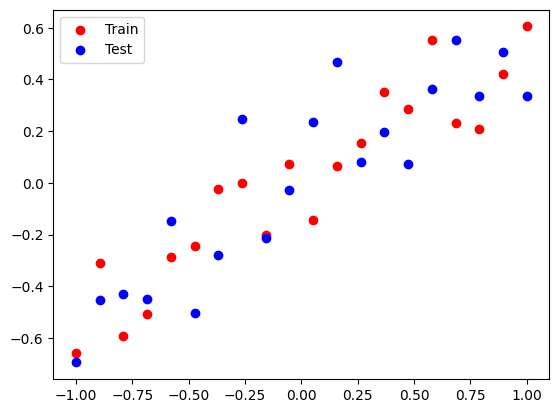

In [6]:
plt.scatter(X_train, y_train, c='red', label='Train')
plt.scatter(X_test, y_test, c='blue', label='Test')
plt.legend()
plt.show()

# Regression Model

In [7]:
model_1 = Sequential()
model_1.add(Dense(128, input_dim=1, activation="relu"))
model_1.add(Dense(128, activation="relu"))
model_1.add(Dense(1, activation="linear"))
adam = Adam(learning_rate=0.01)
model_1.compile(loss='mse', optimizer=adam, metrics=['mse'])
history = model_1.fit(X_train, y_train, epochs=500,
                    validation_data = (X_test, y_test),
                    verbose=False)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
# evaluate the model
_, train_mse = model_1.evaluate(X_train, y_train, verbose=0)
_, test_mse = model_1.evaluate(X_test, y_test, verbose=0)
print('Train: {}, Test: {}'.format(train_mse, test_mse))

Train: 0.0037039197050035, Test: 0.04455164819955826


In [9]:
y_pred_1 = model_1.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step


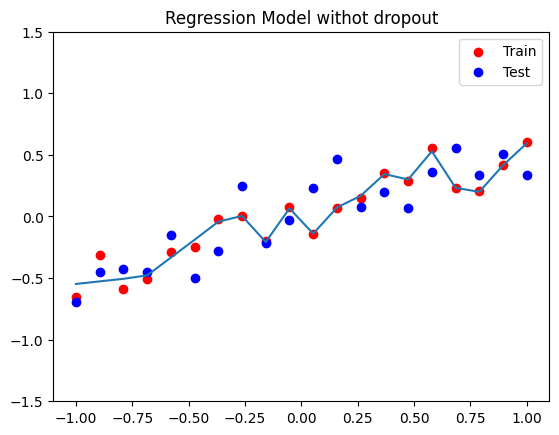

In [10]:
plt.figure()
plt.scatter(X_train, y_train, c='red', label='Train')
plt.scatter(X_test, y_test, c='blue', label='Test')
plt.plot(X_test, y_pred_1)
plt.legend()
plt.ylim((-1.5, 1.5))
plt.title('Regression Model withot dropout')
plt.show()

> eikhane dekha jacche choto point capture korche

> here we seen the overfitting because the curve occiliates i.e curve is not smooth

> to overcome the problem we need to apply dropout

# Applying Dropout Model

In [11]:
model_2 = Sequential()
model_2.add(Dense(128, input_dim=1, activation="relu"))
model_2.add(Dropout(0.2)) # dropout used
model_2.add(Dense(128, activation="relu"))
model_2.add(Dropout(0.2))
model_2.add(Dense(1, activation="linear"))
adam = Adam(learning_rate=0.01)
model_2.compile(loss='mse', optimizer=adam, metrics=['mse'])

drop_out_history = model_2.fit(X_train, y_train, epochs=500,
                               validation_data = (X_test, y_test),
                               verbose=False)

In [12]:
# evaluate the model
_, train_mse = model_2.evaluate(X_train, y_train, verbose=0)
_, test_mse = model_2.evaluate(X_test, y_test, verbose=0)
print('Train: {}, Test: {}'.format(train_mse, test_mse))

Train: 0.01175372488796711, Test: 0.038832224905490875


In [13]:
y_pred_2 = model_2.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 353ms/step


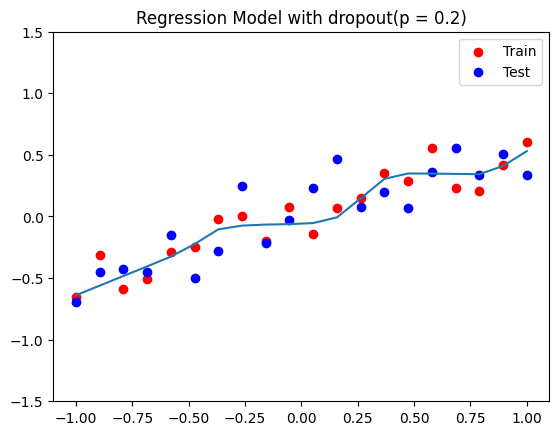

In [16]:
plt.figure()
plt.scatter(X_train, y_train, c='red', label='Train')
plt.scatter(X_test, y_test, c='blue', label='Test')
plt.plot(X_test, y_pred_2)
plt.legend()
plt.ylim((-1.5, 1.5))
plt.title('Regression Model with dropout(p = 0.2)')
plt.show()

In [17]:
model_2 = Sequential()
model_2.add(Dense(128, input_dim=1, activation="relu"))
model_2.add(Dropout(0.5)) # dropout used
model_2.add(Dense(128, activation="relu"))
model_2.add(Dropout(0.5))
model_2.add(Dense(1, activation="linear"))
adam = Adam(learning_rate=0.01)
model_2.compile(loss='mse', optimizer=adam, metrics=['mse'])

drop_out_history = model_2.fit(X_train, y_train, epochs=500, validation_data = (X_test, y_test), verbose=1)

Epoch 1/500


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - loss: 0.0948 - mse: 0.0948 - val_loss: 0.0300 - val_mse: 0.0300
Epoch 2/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 234ms/step - loss: 0.0420 - mse: 0.0420 - val_loss: 0.0480 - val_mse: 0.0480
Epoch 3/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 486ms/step - loss: 0.1197 - mse: 0.1197 - val_loss: 0.0317 - val_mse: 0.0317
Epoch 4/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 357ms/step - loss: 0.0223 - mse: 0.0223 - val_loss: 0.0357 - val_mse: 0.0357
Epoch 5/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - loss: 0.0196 - mse: 0.0196 - val_loss: 0.0402 - val_mse: 0.0402
Epoch 6/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - loss: 0.0577 - mse: 0.0577 - val_loss: 0.0419 - val_mse: 0.0419
Epoch 7/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - loss: 0.0618 - mse: 0.0618 - val_loss: 0.0409 - val_mse: 0.0409
Epoch 8/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - loss: 0.0309 - mse: 0.0309 - val_loss: 0.0370 - val_mse: 0.0370
Epoch 9/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - loss: 0.0370 - mse: 0.0370 - va

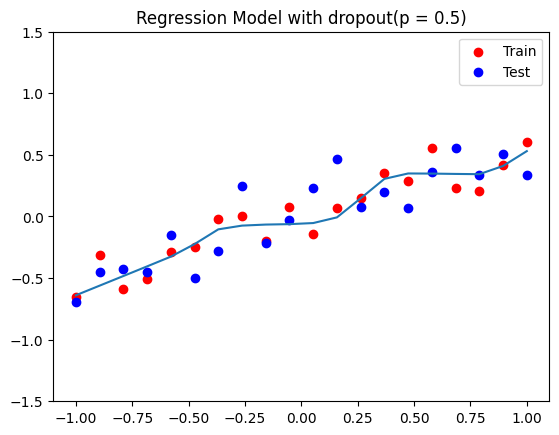

In [18]:
plt.figure()
plt.scatter(X_train, y_train, c='red', label='Train')
plt.scatter(X_test, y_test, c='blue', label='Test')
plt.plot(X_test, y_pred_2)
plt.legend()
plt.ylim((-1.5, 1.5))
plt.title('Regression Model with dropout(p = 0.5)')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


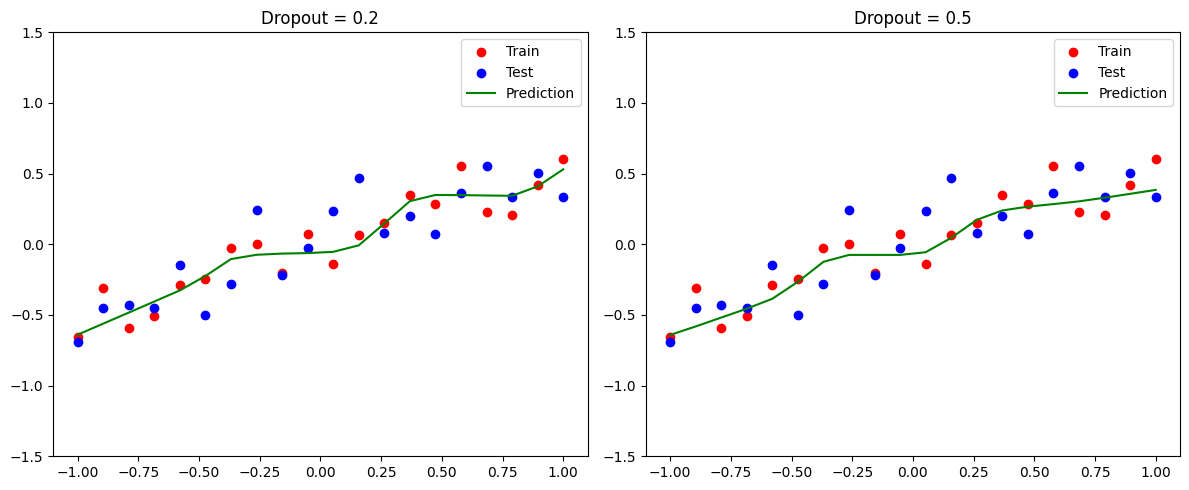

In [20]:
# Predict with the latest model (dropout = 0.5)
y_pred_dropout_05 = model_2.predict(X_test)

# Note: model_2 was overwritten with the 0.5 dropout model.
# y_pred_2 contains the predictions from the 0.2 dropout model trained earlier.

plt.figure(figsize=(12, 5))

# Plot for Dropout = 0.2
plt.subplot(1, 2, 1)
plt.scatter(X_train, y_train, c='red', label='Train')
plt.scatter(X_test, y_test, c='blue', label='Test')
plt.plot(X_test, y_pred_2, color='green', label='Prediction')
plt.ylim((-1.5, 1.5))
plt.title('Dropout = 0.2')
plt.legend()

# Plot for Dropout = 0.5
plt.subplot(1, 2, 2)
plt.scatter(X_train, y_train, c='red', label='Train')
plt.scatter(X_test, y_test, c='blue', label='Test')
plt.plot(X_test, y_pred_dropout_05, color='green', label='Prediction')
plt.ylim((-1.5, 1.5))
plt.title('Dropout = 0.5')
plt.legend()

plt.tight_layout()
plt.show()

# Observations:

> Dropout = 0.2: The prediction curve (green line) shows some moderate smoothing but still attempts to follow some local variations in the training data.

> Dropout = 0.5: The prediction curve is even smoother and acts more like a regularized line, reducing the tendency to overfit noisy individual points in the training dataset.